### The mock kiDS images

d:\Python\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
An error occurred while trying to fetch models/GGL_UNet_diffusion_model: Error no file named diffusion_pytorch_model.safetensors found in directory models/GGL_UNet_diffusion_model.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


shape of the noise image: torch.Size([100, 4, 64, 64])
shape of the fore/back_image image: torch.Size([100, 1, 64, 64]) torch.Size([100, 1, 64, 64])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.84190106..1.1392593].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.11209393..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.708654].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.22163464..5.680814].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.3242888..2.9887774].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.592883..3.3966913].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.08553478..1.0].
Cli

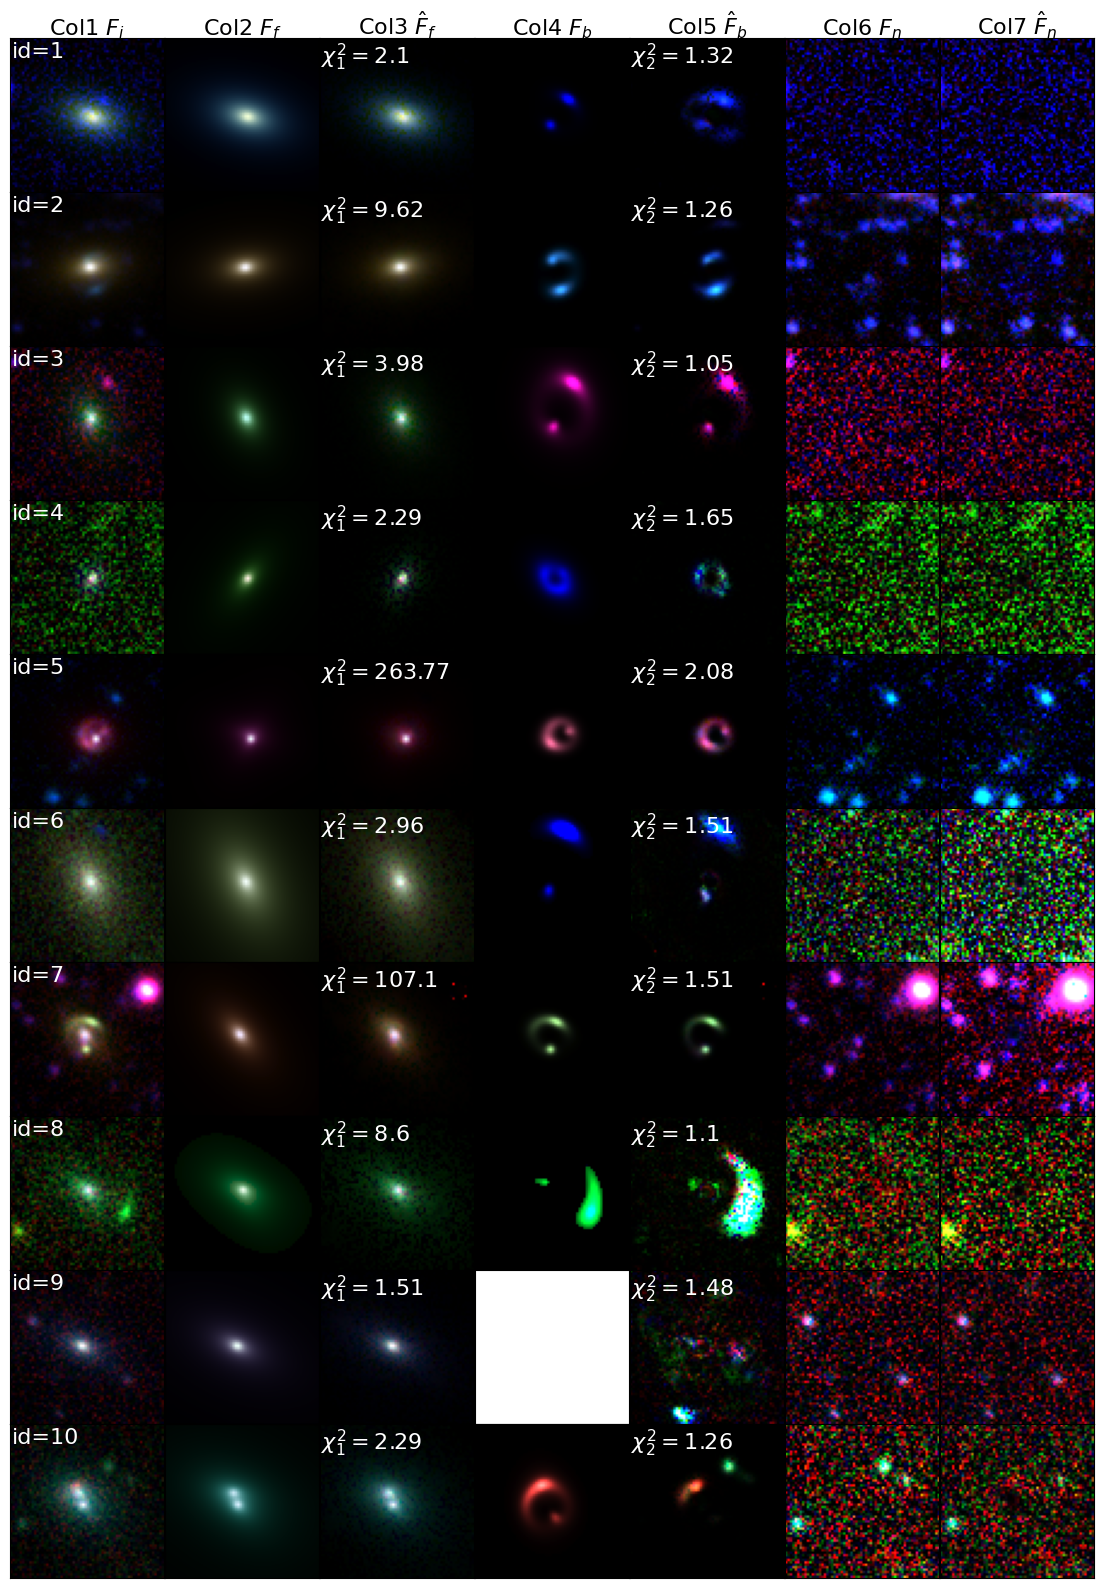

In [1]:
import diffusion_model, torch, plot_image
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table

ggl_unet = diffusion_model.GGL_UNet()
ggl_unet.cfg['train_set'] = 'color_images.fits'
ggl_unet.Init()
ggl_unet.load_training_data(frac=0)
# pred_mock 运行前强制模型和数据在 CPU 上，避免 numpy 转换报错
ggl_unet.device = torch.device('cpu')
ggl_unet.pred_mock([0, 10], mode='def', timestep=10, load_model=True)
fname = 'results/GGL_UNet_diffusion_model_pred_mock_def.fits'
data = Table.read(fname)
plot_image.display_mock_image(data[0:10])

### The KiDS candidates

An error occurred while trying to fetch models/GGL_UNet_diffusion_model: Error no file named diffusion_pytorch_model.safetensors found in directory models/GGL_UNet_diffusion_model.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


shape of the noise image: torch.Size([100, 4, 64, 64])
shape of the fore/back_image image: torch.Size([100, 1, 64, 64]) torch.Size([100, 1, 64, 64])


TypeError: 'Axes' object is not subscriptable

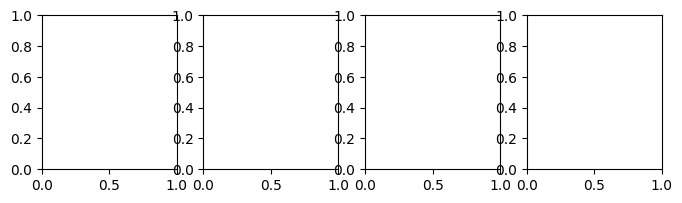

In [13]:
from astropy.table import hstack
import diffusion_model, torch, plot_image
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table
import diffusion_model, torch, plot_image
ggl_unet = diffusion_model.GGL_UNet()
ggl_unet.cfg['train_set'] = 'color_images.fits'
ggl_unet.Init()
ggl_unet.load_training_data(frac=0)

# data_lens = Table.read('results/kids_lens.fits')
data_lens = Table.read('data/data_model_format.fits')
color_images, weigh_image, RA, DEC = data_lens['image'], data_lens['weight'], data_lens['RA'], data_lens['DEC']

# 兼容 numpy 2.0，处理 newbyteorder 被移除的问题
if hasattr(color_images, 'dtype') and hasattr(color_images, 'byteswap') and color_images.dtype.byteorder != '=':
    color_images = color_images.byteswap().view(color_images.dtype.newbyteorder('='))

# 保证模型和数据都在 CPU 上，避免 device 不一致报错
ggl_unet.device = torch.device('cpu')
ggl_unet.pred_real(color_images, weight=weigh_image, RA=RA, DEC=DEC, timestep=25, load_model=True, save_name='pred_real_lens')
fname = 'results/GGL_UNet_diffusion_model_pred_real_lens.fits'
data = Table.read(fname)
plot_image.display_real_image(data[0:])